# Instituto Federal do Espírito Santo (IFES) – Campus Serra
### Programa de Pós-Graduação em Computação Aplicada (PPComp) – Mestrado

**Disciplina:** Redes Neurais Artificiais (2026/2)
**Professor:** Francisco de Assis Boldt
**Aluno:** Leonardo Cruz de Andrade
**Data de entrega:** 18 de novembro de 2026

## Atividade 04 – Análise de sentimento do IMDB com a classe `pipeline` do Hugging Face

A tarefa é usar a classe `pipeline` da biblioteca `transformers` para classificar o sentimento das resenhas da base IMDB, tomando como guia a seção [*Behind the pipeline*](https://huggingface.co/learn/llm-course/chapter2/2?fw=pt) do curso de NLP do Hugging Face. Por isso o notebook tem duas partes: primeiro abro o `pipeline` e refaço à mão as três etapas que ele executa; depois uso o `pipeline` na base.

Comparo dois modelos:
- `distilbert-base-uncased-finetuned-sst-2-english`, o modelo padrão do `pipeline("sentiment-analysis")` e o mesmo usado no curso. Foi ajustado no SST-2, que tem frases curtas de críticas de cinema, e nunca viu o IMDB.
- `lvwerra/distilbert-imdb`, o modelo usado na `aula12c`, ajustado no conjunto de treino do próprio IMDB.

**Organização do notebook**
1. O que acontece dentro do `pipeline`
2. As três etapas feitas à mão
3. A base IMDB
4. Classificação de uma amostra do teste
5. Resenhas longas e o limite de 512 tokens
6. Confiança das previsões
7. Olhando os erros
8. Conclusões

Código de referência da disciplina: [fboldt/aulasann](https://github.com/fboldt/aulasann) (`aula12c_huggingface`).

### Ambiente de execução

As saídas deste notebook foram geradas em CPU, com Python 3.10.4 e as versões abaixo. Para obter os mesmos números, crie um ambiente novo com Python 3.10 e Jupyter e instale:

```
pip install numpy==2.2.6 pandas==2.3.3 matplotlib==3.10.6 scikit-learn==1.7.2 torch==2.14.1 transformers==5.20.2 tokenizers==0.23.3 safetensors==0.8.0 huggingface_hub==2.3.0 pyarrow==25.0.1
```

A célula seguinte compara essas versões com as instaladas. Com outras versões (no Colab, por exemplo) o notebook roda normalmente, mas os resultados podem mudar nas últimas casas decimais.

Na primeira execução são baixados a base e os dois modelos (cerca de 540 MB no total). Os modelos e a cópia da base no Hugging Face Hub são carregados numa versão (*commit*) fixa, para que uma atualização futura deles não mude os resultados.

In [1]:
from importlib.metadata import version, PackageNotFoundError
import platform

# versões usadas para gerar as saídas deste notebook
VERSOES_USADAS = {
    "numpy": "2.2.6",
    "pandas": "2.3.3",
    "matplotlib": "3.10.6",
    "scikit-learn": "1.7.2",
    "torch": "2.14.1",
    "transformers": "5.20.2",
    "tokenizers": "0.23.3",
    "safetensors": "0.8.0",
    "huggingface_hub": "2.3.0",
    "pyarrow": "25.0.1",
}

diferentes = 0 if platform.python_version().startswith("3.10.") else 1
print(f"{'Python':16s} usada 3.10.4     instalada {platform.python_version()}")
for pacote, usada in VERSOES_USADAS.items():
    try:
        instalada = version(pacote)
    except PackageNotFoundError:
        instalada = "não instalado"
    igual = instalada.split("+")[0] == usada
    diferentes += not igual
    print(f"{pacote:16s} usada {usada:10s} instalada {instalada}{'' if igual else '   <- diferente'}")

if diferentes == 0:
    print("\nambiente igual ao usado nas saídas")
else:
    print(f"\n{diferentes} item(ns) com versão diferente: os números podem variar nas últimas casas")

Python           usada 3.10.4     instalada 3.10.4
numpy            usada 2.2.6      instalada 2.2.6
pandas           usada 2.3.3      instalada 2.3.3
matplotlib       usada 3.10.6     instalada 3.10.6
scikit-learn     usada 1.7.2      instalada 1.7.2
torch            usada 2.14.1     instalada 2.14.1
transformers     usada 5.20.2     instalada 5.20.2
tokenizers       usada 0.23.3     instalada 0.23.3
safetensors      usada 0.8.0      instalada 0.8.0
huggingface_hub  usada 2.3.0      instalada 2.3.0
pyarrow          usada 25.0.1     instalada 25.0.1

ambiente igual ao usado nas saídas


## 1. O que acontece dentro do `pipeline`

Uma chamada como `pipeline("sentiment-analysis")("I hate this so much!")` esconde três etapas:

1. **Tokenização.** O `AutoTokenizer` quebra o texto em subpalavras (*WordPiece*, no caso do DistilBERT), troca cada uma pelo seu número no vocabulário, acrescenta os tokens especiais `[CLS]` e `[SEP]` e devolve os tensores `input_ids` e `attention_mask`. A máscara marca quais posições são texto e quais são preenchimento (*padding*).
2. **Modelo.** O `AutoModelForSequenceClassification` passa os tensores pelas 6 camadas do DistilBERT, que produzem um vetor de 768 dimensões para cada token, e uma camada linear transforma o vetor do `[CLS]` em dois números, os *logits*.
3. **Pós-processamento.** Uma *softmax* converte os logits em probabilidades, e o `id2label` do modelo dá o nome da classe mais provável.

Primeiro rodo o `pipeline` nas duas frases do curso; na seção seguinte, refaço as três etapas e confiro se os números batem.

In [2]:
import os
import shutil
import time
import tarfile
import urllib.request
import warnings
from pathlib import Path

os.environ["TOKENIZERS_PARALLELISM"] = "false"
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message="IProgress not found")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

import transformers
import huggingface_hub
from transformers import pipeline, AutoTokenizer, AutoModel, AutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

# esconde as barras de progresso e avisos de download, que poluem a saída
transformers.utils.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
huggingface_hub.utils.logging.set_verbosity_error()
huggingface_hub.utils.disable_progress_bars()

SEED = 42
torch.manual_seed(SEED)

print("transformers", transformers.__version__, "| torch", torch.__version__,
      "| threads de CPU:", torch.get_num_threads())

transformers 5.20.2 | torch 2.14.1+cpu | threads de CPU: 6


In [3]:
MODELO_SST2 = "distilbert-base-uncased-finetuned-sst-2-english"
MODELO_IMDB = "lvwerra/distilbert-imdb"
# versões (commits) dos modelos no Hugging Face Hub usadas para gerar as saídas
REVISAO = {MODELO_SST2: "714eb0fa89d2f80546fda750413ed43d93601a13",
           MODELO_IMDB: "0fc02cd68445b599a9cb2da2368050e7fb31d29a"}

frases = [
    "I've been waiting for a HuggingFace course my whole life.",
    "I hate this so much!",
]

classificador = pipeline("sentiment-analysis", model=MODELO_SST2, revision=REVISAO[MODELO_SST2], device="cpu")
for frase, saida in zip(frases, classificador(frases)):
    print(f"{saida['label']:<8} {saida['score']:.4f}  {frase}")

POSITIVE 0.9598  I've been waiting for a HuggingFace course my whole life.
NEGATIVE 0.9995  I hate this so much!


São os mesmos valores do curso: 0,9598 para a primeira frase e 0,9995 para a segunda.

## 2. As três etapas feitas à mão

### 2.1 Tokenização

In [4]:
tokenizador = AutoTokenizer.from_pretrained(MODELO_SST2, revision=REVISAO[MODELO_SST2])
entradas = tokenizador(frases, padding=True, truncation=True, return_tensors="pt")

print("formato de input_ids:", tuple(entradas["input_ids"].shape))
print("tamanho do vocabulário:", tokenizador.vocab_size)
for i in range(len(frases)):
    tokens = tokenizador.convert_ids_to_tokens(entradas["input_ids"][i])
    print(f"\nfrase {i + 1}:")
    print("  tokens   ", tokens)
    print("  ids      ", entradas["input_ids"][i].tolist())
    print("  máscara  ", entradas["attention_mask"][i].tolist())

formato de input_ids: (2, 16)
tamanho do vocabulário: 30522

frase 1:
  tokens    ['[CLS]', 'i', "'", 've', 'been', 'waiting', 'for', 'a', 'hugging', '##face', 'course', 'my', 'whole', 'life', '.', '[SEP]']
  ids       [101, 1045, 1005, 2310, 2042, 3403, 2005, 1037, 17662, 12172, 2607, 2026, 2878, 2166, 1012, 102]
  máscara   [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

frase 2:
  tokens    ['[CLS]', 'i', 'hate', 'this', 'so', 'much', '!', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
  ids       [101, 1045, 5223, 2023, 2061, 2172, 999, 102, 0, 0, 0, 0, 0, 0, 0, 0]
  máscara   [1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0]


A primeira frase vira 16 tokens: o `[CLS]` no início (id 101), o `[SEP]` no fim (id 102) e 14 subpalavras no meio. "HuggingFace" não está no vocabulário e é quebrado em `hugging`, `##face`; o `##` indica que o pedaço continua a palavra anterior. A segunda frase é mais curta e foi completada com zeros (`[PAD]`) até 16 posições, e a máscara marca essas posições com 0 para o modelo ignorá-las.

### 2.2 O modelo

O curso mostra o modelo em dois níveis. O `AutoModel` carrega só o corpo do DistilBERT, sem a camada de classificação, e devolve um vetor por token (o *hidden state*). O `AutoModelForSequenceClassification` acrescenta a "cabeça" que transforma isso em logits.

In [5]:
corpo = AutoModel.from_pretrained(MODELO_SST2, revision=REVISAO[MODELO_SST2])
with torch.no_grad():
    estados = corpo(**entradas).last_hidden_state
print("saída do AutoModel (last_hidden_state):", tuple(estados.shape), "-> (frases, tokens, dimensão)")

modelo = AutoModelForSequenceClassification.from_pretrained(MODELO_SST2, revision=REVISAO[MODELO_SST2]).eval()
with torch.no_grad():
    logits = modelo(**entradas).logits
print("saída do AutoModelForSequenceClassification (logits):", tuple(logits.shape))
print(logits.numpy().round(4))
print(f"\nparâmetros: corpo {sum(p.numel() for p in corpo.parameters()):,}"
      f" | com a cabeça {sum(p.numel() for p in modelo.parameters()):,}".replace(",", "."))

saída do AutoModel (last_hidden_state): (2, 16, 768) -> (frases, tokens, dimensão)


saída do AutoModelForSequenceClassification (logits): (2, 2)
[[-1.5607  1.6123]
 [ 4.1692 -3.3464]]

parâmetros: corpo 66.362.880 | com a cabeça 66.955.010


### 2.3 Pós-processamento

Os logits não são probabilidades: podem ser negativos e não somam 1. A *softmax* resolve isso:

$$P(\text{classe } k) = \frac{e^{z_k}}{\sum_j e^{z_j}}$$

In [6]:
probs = F.softmax(logits, dim=-1)
print("rótulos do modelo:", modelo.config.id2label)

saidas_pipeline = classificador(frases)
for i, frase in enumerate(frases):
    k = int(probs[i].argmax())
    print(f"\nfrase {i + 1}: P(NEGATIVE) = {probs[i, 0]:.4f}  P(POSITIVE) = {probs[i, 1]:.4f}")
    print(f"  à mão   : {modelo.config.id2label[k]} {probs[i, k]:.6f}")
    print(f"  pipeline: {saidas_pipeline[i]['label']} {saidas_pipeline[i]['score']:.6f}")

rótulos do modelo: {0: 'NEGATIVE', 1: 'POSITIVE'}

frase 1: P(NEGATIVE) = 0.0402  P(POSITIVE) = 0.9598
  à mão   : POSITIVE 0.959805
  pipeline: POSITIVE 0.959805

frase 2: P(NEGATIVE) = 0.9995  P(POSITIVE) = 0.0005
  à mão   : NEGATIVE 0.999456
  pipeline: NEGATIVE 0.999456


Os resultados à mão coincidem com os do `pipeline`. Ele não faz nada além dessas três etapas, e as escolhas que importam ficam escondidas nos padrões: o modelo usado quando nenhum é indicado, o corte em 512 tokens (que só acontece se `truncation=True` for passado) e o nome das classes.

## 3. A base IMDB

A *Large Movie Review Dataset* (Maas et al., 2011) tem 50.000 resenhas do site IMDB, divididas em 25.000 para treino e 25.000 para teste, cada metade com 12.500 positivas e 12.500 negativas. Uma resenha é negativa quando a nota dada pelo autor é 4 ou menos (em 10), e positiva quando é 7 ou mais. As notas 5 e 6 ficaram de fora. São textos longos, com bastante resumo do enredo, comparação com outros filmes e ironia.

Uso só a parte de **teste**, porque o modelo `lvwerra/distilbert-imdb` foi ajustado na parte de treino.

O código tenta, nesta ordem:
- ler o arquivo oficial `aclImdb_v1.tar.gz` da pasta `data/`;
- baixá-lo do site da Stanford;
- se o site não responder, usar a cópia da mesma base que o grupo de NLP de Stanford publica no Hugging Face Hub (`stanfordnlp/imdb`).

Ao preparar este notebook o site da Stanford não respondeu, e a base veio da cópia do Hub. Para que a amostra seja a mesma qualquer que seja a origem, as resenhas são ordenadas pelo texto antes do sorteio.

In [7]:
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
URL_STANFORD = "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"
ARQUIVO_TAR = DATA_DIR / "aclImdb_v1.tar.gz"
REVISAO_BASE_HUB = "e6281661ce1c48d982bc483cf8a173c1bbeb5d31"  # commit da cópia stanfordnlp/imdb


def ler_teste_do_tar(caminho):
    # lê aclImdb/test/{pos,neg}/*.txt direto do .tar.gz, sem extrair os 100 mil arquivos
    linhas = []
    with tarfile.open(caminho, "r:gz") as tar:
        for membro in tar:
            partes = membro.name.split("/")
            if membro.isfile() and len(partes) == 4 and partes[1] == "test" and partes[2] in ("pos", "neg"):
                texto = tar.extractfile(membro).read().decode("utf-8")
                linhas.append({"text": texto, "label": int(partes[2] == "pos")})
    return pd.DataFrame(linhas)


def carregar_teste():
    if not ARQUIVO_TAR.exists():
        try:
            print("baixando", URL_STANFORD)
            with urllib.request.urlopen(URL_STANFORD, timeout=30) as resposta, open(ARQUIVO_TAR, "wb") as f:
                shutil.copyfileobj(resposta, f)
        except Exception as erro:
            ARQUIVO_TAR.unlink(missing_ok=True)
            print("site da Stanford indisponível:", type(erro).__name__)
    if ARQUIVO_TAR.exists():
        return ler_teste_do_tar(ARQUIVO_TAR), "aclImdb_v1.tar.gz (Stanford)"
    caminho = huggingface_hub.hf_hub_download("stanfordnlp/imdb", "plain_text/test-00000-of-00001.parquet",
                                              repo_type="dataset", revision=REVISAO_BASE_HUB, local_dir=DATA_DIR / "stanfordnlp_imdb")
    return pd.read_parquet(caminho)[["text", "label"]], "stanfordnlp/imdb (Hugging Face Hub)"


teste, origem = carregar_teste()
teste = teste.sort_values(["label", "text"], kind="stable").reset_index(drop=True)
print("origem:", origem)
print("resenhas de teste:", len(teste), "| por classe:", teste["label"].value_counts().sort_index().to_dict(),
      "(0 = negativa, 1 = positiva)")

baixando https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz


site da Stanford indisponível: URLError


origem: stanfordnlp/imdb (Hugging Face Hub)
resenhas de teste: 25000 | por classe: {0: 12500, 1: 12500} (0 = negativa, 1 = positiva)


### 3.1 Amostra e tamanho das resenhas

No meu computador, só com CPU, o DistilBERT classifica umas 8 resenhas por segundo. As 25.000 resenhas do teste com dois modelos levariam perto de uma hora e quarenta, então sorteio uma amostra estratificada de **2.000 resenhas** (1.000 de cada classe). Com esse tamanho, a margem de erro da acurácia (intervalo de 95%) fica em torno de ±1,3 ponto percentual, o que basta para comparar os modelos. Para rodar no teste inteiro, basta trocar `N_POR_CLASSE` por `None`.

O único pré-processamento é trocar as quebras de linha em HTML (`<br />`) por espaço.

resenhas na amostra: 2000 | por classe: {0: 1000, 1: 1000}
palavras por resenha: mediana 171, máximo 1003
tokens por resenha:   mediana 217, média 297, máximo 1338
resenhas com mais de 512 tokens: 268 (13.4%)


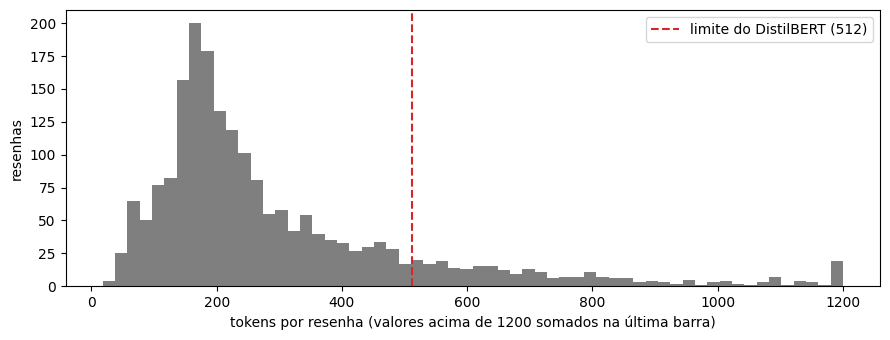

In [8]:
N_POR_CLASSE = 1000

if N_POR_CLASSE is None:
    amostra = teste.copy()
else:
    amostra = pd.concat([g.sample(n=N_POR_CLASSE, random_state=SEED) for _, g in teste.groupby("label")])
amostra = amostra.sample(frac=1, random_state=SEED).reset_index(drop=True)
amostra["texto"] = amostra["text"].str.replace("<br />", " ", regex=False)

amostra["palavras"] = amostra["texto"].str.split().str.len()
amostra["tokens"] = [len(ids) for ids in tokenizador(amostra["texto"].tolist())["input_ids"]]
longa = amostra["tokens"] > 512

print("resenhas na amostra:", len(amostra), "| por classe:", amostra["label"].value_counts().sort_index().to_dict())
print(f"palavras por resenha: mediana {amostra['palavras'].median():.0f}, máximo {amostra['palavras'].max()}")
print(f"tokens por resenha:   mediana {amostra['tokens'].median():.0f}, média {amostra['tokens'].mean():.0f}, "
      f"máximo {amostra['tokens'].max()}")
print(f"resenhas com mais de 512 tokens: {longa.sum()} ({longa.mean():.1%})")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(amostra["tokens"].clip(upper=1200), bins=60, color="tab:gray")
ax.axvline(512, color="tab:red", linestyle="--", label="limite do DistilBERT (512)")
ax.set_xlabel("tokens por resenha (valores acima de 1200 somados na última barra)")
ax.set_ylabel("resenhas")
ax.legend()
plt.tight_layout()
plt.show()

O DistilBERT só enxerga 512 posições. Nas resenhas maiores que isso, o `pipeline` com `truncation=True` descarta o final do texto, e às vezes é justamente no final que o autor dá o veredito. Volto a isso na seção 5.

Antes de usar o `pipeline` na base, repito a conferência da seção 2 com resenhas de verdade, escolhendo as 16 mais longas da amostra, todas cortadas em 512 tokens.

In [9]:
textos_longos = amostra.nlargest(16, "tokens")["texto"].tolist()

entradas = tokenizador(textos_longos, padding=True, truncation=True, max_length=512, return_tensors="pt")
with torch.no_grad():
    p_mao = F.softmax(modelo(**entradas).logits, dim=-1)[:, 1].numpy()

saidas = classificador(textos_longos, batch_size=16, truncation=True, max_length=512)
p_pipe = np.array([s["score"] if s["label"] == "POSITIVE" else 1 - s["score"] for s in saidas])

print("formato da entrada:", tuple(entradas["input_ids"].shape))
print(f"maior diferença em P(POSITIVE) entre à mão e pipeline: {np.abs(p_mao - p_pipe).max():.1e}")

formato da entrada: (16, 512)
maior diferença em P(POSITIVE) entre à mão e pipeline: 7.2e-08


## 4. Classificação da amostra

Para ganhar tempo, a função abaixo entrega as resenhas ao `pipeline` em ordem de tamanho. Assim cada lote junta textos de comprimento parecido e quase não há *padding*. Depois as previsões voltam para a ordem original. Guardo a probabilidade da classe positiva, que serve para a curva ROC e para a análise de confiança.

In [10]:
def prob_positiva(pipe, textos, batch_size=16):
    ordem = np.argsort([len(t) for t in textos])
    saidas = pipe([textos[i] for i in ordem], batch_size=batch_size, truncation=True, max_length=512)
    p = np.empty(len(textos))
    for i, s in zip(ordem, saidas):
        p[i] = s["score"] if s["label"] == "POSITIVE" else 1.0 - s["score"]
    return p


modelos = {"SST-2": MODELO_SST2, "IMDB": MODELO_IMDB}
pipes = {"SST-2": classificador,
         "IMDB": pipeline("sentiment-analysis", model=MODELO_IMDB, revision=REVISAO[MODELO_IMDB], device="cpu")}
print("rótulos do modelo IMDB:", pipes["IMDB"].model.config.id2label)

textos = amostra["texto"].tolist()
for nome, pipe in pipes.items():
    t0 = time.time()
    amostra[f"p_{nome}"] = prob_positiva(pipe, textos)
    seg = time.time() - t0
    print(f"{nome}: {len(textos)} resenhas em {seg / 60:.1f} min ({len(textos) / seg:.1f} por segundo)")

rótulos do modelo IMDB: {0: 'NEGATIVE', 1: 'POSITIVE'}


SST-2: 2000 resenhas em 3.0 min (11.2 por segundo)


IMDB: 2000 resenhas em 3.0 min (11.2 por segundo)


In [11]:
y = amostra["label"].to_numpy()
n = len(y)


def intervalo(acc, n):
    m = 1.96 * np.sqrt(acc * (1 - acc) / n)
    return acc - m, acc + m


linhas = []
for nome in pipes:
    p = amostra[f"p_{nome}"].to_numpy()
    pred = (p >= 0.5).astype(int)
    amostra[f"pred_{nome}"] = pred
    acc = accuracy_score(y, pred)
    lo, hi = intervalo(acc, n)
    rep = classification_report(y, pred, output_dict=True)
    linhas.append({"modelo": nome, "acurácia (%)": 100 * acc, "IC 95% (%)": f"{100 * lo:.1f} a {100 * hi:.1f}",
                   "F1 negativa": rep["0"]["f1-score"], "F1 positiva": rep["1"]["f1-score"],
                   "AUC": roc_auc_score(y, p), "erros": int((pred != y).sum())})

tabela = pd.DataFrame(linhas).set_index("modelo")
display(tabela.round({"acurácia (%)": 2, "F1 negativa": 3, "F1 positiva": 3, "AUC": 4}))

concordam = (amostra["pred_SST-2"] == amostra["pred_IMDB"])
print(f"os dois modelos concordam em {concordam.mean():.1%} das resenhas; "
      f"quando concordam, acertam {(amostra.loc[concordam, 'pred_IMDB'] == amostra.loc[concordam, 'label']).mean():.1%}")

,acurácia (%),IC 95% (%),F1 negativa,F1 positiva,AUC,erros
modelo,,,,,,
SST-2,89.20,87.8 a 90.6,0.895,0.889,0.9592,216
IMDB,93.15,92.0 a 94.3,0.932,0.931,0.9796,137


os dois modelos concordam em 92.5% das resenhas; quando concordam, acertam 94.5%


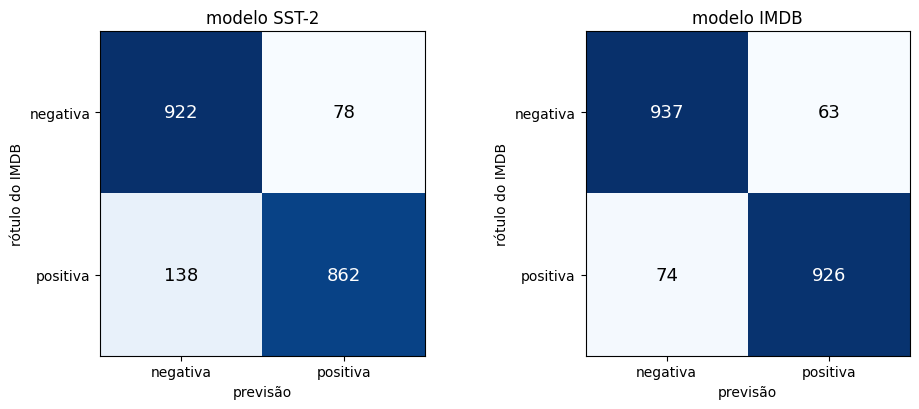

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, nome in zip(axes, pipes):
    cm = confusion_matrix(y, amostra[f"pred_{nome}"])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["negativa", "positiva"])
    ax.set_yticks([0, 1], ["negativa", "positiva"])
    ax.set_xlabel("previsão")
    ax.set_ylabel("rótulo do IMDB")
    ax.set_title(f"modelo {nome}")
plt.tight_layout()
plt.show()

O modelo ajustado no IMDB acertou **93,2%** da amostra, com intervalo de 92,0% a 94,3%. O modelo SST-2 acertou **89,2%**, com intervalo de 87,8% a 90,6%. Os intervalos não se sobrepõem, e a AUC também sobe, de 0,959 para 0,980.

Alguns pontos que chamam a atenção:
- **Comparação com a aula.** Na `aula12c` o mesmo `lvwerra/distilbert-imdb` foi aplicado às 25.000 resenhas de teste e chegou a 92,8%. O valor cai dentro do intervalo da minha amostra, o que indica que 2.000 resenhas representam bem o conjunto inteiro.
- **SST-2 sem ajuste.** O modelo padrão do `pipeline` nunca viu uma resenha do IMDB, foi treinado com frases curtas, e mesmo assim acerta quase 9 em cada 10. O ajuste fino no IMDB reduz os erros de 216 para 137, cerca de 37% a menos.
- **Direção dos erros.** O modelo SST-2 erra mais com as resenhas positivas (138 classificadas como negativas, contra 78 no sentido oposto), ou seja, puxa para o negativo. O modelo IMDB é equilibrado (74 e 63).
- **Concordância.** Os dois modelos dão a mesma resposta em 92,5% das resenhas, e nesses casos acertam 94,5%.

## 5. Resenhas longas e o limite de 512 tokens

Separo a acurácia entre as resenhas que cabem inteiras no modelo e as que foram cortadas. Para as cortadas, testo também a alternativa de manter o **final** do texto em vez do começo, o que se faz criando o tokenizador com `truncation_side="left"` e passando-o ao `pipeline`. A ideia é que muita gente termina a resenha com a conclusão ("8/10, recomendo").

In [13]:
idx_longas = np.flatnonzero(longa.to_numpy())
textos_longas = [textos[i] for i in idx_longas]

linhas = []
for nome, ckpt in modelos.items():
    tok_final = AutoTokenizer.from_pretrained(ckpt, revision=REVISAO[ckpt], truncation_side="left")
    pipe_final = pipeline("sentiment-analysis", model=pipes[nome].model, tokenizer=tok_final, device="cpu")
    p_final = prob_positiva(pipe_final, textos_longas)
    pred = amostra[f"pred_{nome}"].to_numpy()
    certo_comeco = pred[longa] == y[longa]
    certo_final = (p_final >= 0.5).astype(int) == y[longa]
    print(f"{nome}: ao manter o final, {(~certo_comeco & certo_final).sum()} resenhas passam a acertar "
          f"e {(certo_comeco & ~certo_final).sum()} passam a errar")
    linhas.append({
        "modelo": nome,
        f"até 512 tokens ({(~longa).sum()})": 100 * (pred[~longa] == y[~longa]).mean(),
        f"mais de 512 – começo ({longa.sum()})": 100 * (pred[longa] == y[longa]).mean(),
        f"mais de 512 – final ({longa.sum()})": 100 * ((p_final >= 0.5).astype(int) == y[longa]).mean(),
    })

display(pd.DataFrame(linhas).set_index("modelo").round(1))

SST-2: ao manter o final, 22 resenhas passam a acertar e 16 passam a errar


IMDB: ao manter o final, 13 resenhas passam a acertar e 9 passam a errar


,até 512 tokens (1732),mais de 512 – começo (268),mais de 512 – final (268)
modelo,,,
SST-2,89.7,86.2,88.4
IMDB,93.2,92.9,94.4


- **SST-2.** Para este modelo, as resenhas cortadas são mais difíceis: ele acerta 86,2% delas, contra 89,7% das que cabem inteiras. Mantendo o final em vez do começo, sobe para 88,4%.
- **IMDB.** Para este modelo o corte quase não faz diferença (92,9% contra 93,2%), e manter o final dá 94,4%.

Nos dois casos, manter o final ajudou, o que combina com a ideia de que a conclusão costuma vir no fim. Mas a troca mexe nos dois sentidos: no SST-2, 22 resenhas passam a acertar e 16 passam a errar; no modelo IMDB, 13 e 9. O saldo é de 6 e 4 resenhas em 268, dentro da margem de erro de um grupo desse tamanho (cerca de ±4 pontos). Para afirmar com segurança, eu precisaria rodar no teste inteiro, que tem por volta de 3.300 resenhas longas. Outras opções seriam juntar começo e fim, ou dividir a resenha em trechos de 512 tokens e combinar as previsões.

## 6. Confiança das previsões

O `score` devolvido pelo `pipeline` é a probabilidade da classe escolhida. Se ele for útil, os erros devem se concentrar nos *scores* baixos. Os gráficos mostram a distribuição do *score* nos acertos e nos erros, e a tabela mostra o que acontece quando o modelo só responde se tiver confiança acima de um limiar (as demais resenhas iriam para revisão manual).

SST-2: score médio 0.986 nos acertos e 0.901 nos erros; 72 dos 216 erros têm score acima de 0,99
IMDB: score médio 0.960 nos acertos e 0.792 nos erros; 7 dos 137 erros têm score acima de 0,99


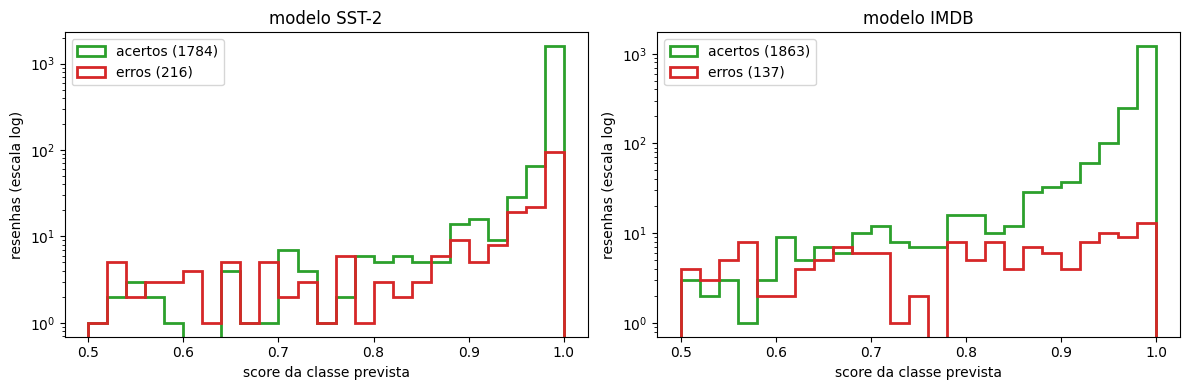

resenhas respondidas (%)  acurácia nelas (%)
modelo limiar                                              
SST-2  0.50                       100.0                89.2
       0.90                        93.2                92.0
       0.99                        78.6                95.4
IMDB   0.50                       100.0                93.2
       0.90                        85.4                97.4
       0.99                        43.4                99.2

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(0.5, 1.0, 26)
linhas = []
for ax, nome in zip(axes, pipes):
    p = amostra[f"p_{nome}"].to_numpy()
    conf = np.maximum(p, 1 - p)
    certo = amostra[f"pred_{nome}"].to_numpy() == y
    ax.hist(conf[certo], bins=bins, histtype="step", linewidth=2, color="tab:green", label=f"acertos ({certo.sum()})")
    ax.hist(conf[~certo], bins=bins, histtype="step", linewidth=2, color="tab:red", label=f"erros ({(~certo).sum()})")
    ax.set_yscale("log")
    ax.set_xlabel("score da classe prevista")
    ax.set_ylabel("resenhas (escala log)")
    ax.set_title(f"modelo {nome}")
    ax.legend(loc="upper left")
    for limiar in [0.5, 0.9, 0.99]:
        sel = conf >= limiar
        linhas.append({"modelo": nome, "limiar": limiar, "resenhas respondidas (%)": 100 * sel.mean(),
                       "acurácia nelas (%)": 100 * certo[sel].mean()})
    print(f"{nome}: score médio {conf[certo].mean():.3f} nos acertos e {conf[~certo].mean():.3f} nos erros; "
          f"{(conf[~certo] >= 0.99).sum()} dos {(~certo).sum()} erros têm score acima de 0,99")
plt.tight_layout()
plt.show()

display(pd.DataFrame(linhas).set_index(["modelo", "limiar"]).round(1))

Os dois modelos dão *scores* mais baixos quando erram, mas de formas bem diferentes:
- **SST-2: confiante demais.** Um terço dos erros (72 de 216) vem com *score* acima de 0,99, e o *score* médio dos erros é 0,90. Pelo histograma, os erros se acumulam perto de 1, junto com os acertos. Minha leitura é que, fora do tipo de texto em que foi treinado, o modelo continua dando respostas extremas.
- **IMDB: mais útil como medida de confiança.** Só 7 dos 137 erros passam de 0,99, e o *score* médio dos erros é 0,79. Com limiar de 0,9, o modelo responde 85,4% das resenhas e acerta 97,4% delas. Com limiar de 0,99, acerta 99,2%, mas responde só 43,4%.

Ou seja, com o modelo ajustado no IMDB dá para separar as resenhas fáceis e mandar as duvidosas para revisão. Com o SST-2, um *score* de 0,99 não garante muita coisa.

## 7. Olhando os erros

Números não dizem por que o modelo erra, então li os erros. Abaixo estão os erros com *score* mais alto do modelo IMDB, isto é, aqueles em que ele estava mais seguro e errou, três em cada direção. Mostro o começo e o fim de cada resenha.

In [15]:
def trecho(texto, n=260):
    if len(texto) <= 2 * n:
        return texto
    return texto[:n].rstrip() + " [...] " + texto[-n:].lstrip()


p = amostra["p_IMDB"]
erros = amostra[amostra["pred_IMDB"] != amostra["label"]].assign(conf=np.maximum(p, 1 - p))
for rotulo, titulo in [(0, "NEGATIVA classificada como positiva"), (1, "POSITIVA classificada como negativa")]:
    print("=" * 100)
    print(f"Resenhas {titulo}")
    print("=" * 100)
    for i, linha in erros[erros["label"] == rotulo].nlargest(3, "conf").iterrows():
        print(f"\n[{i}] score {linha['conf']:.3f} | SST-2 deu P(positiva) = {linha['p_SST-2']:.3f} | "
              f"{linha['tokens']} tokens")
        print(trecho(linha["texto"]))
    print()

Resenhas NEGATIVA classificada como positiva

[1640] score 0.995 | SST-2 deu P(positiva) = 1.000 | 73 tokens
This is definitely one of the best Kung fu movies in the history of Cinema. The screenplay is really well done (which is not often the case for this type of movies) and you can see that Chuck (in one of his first role)is a great actor. The final fight with the sherif deputy in the bullring is a masterpiece!

[1246] score 0.995 | SST-2 deu P(positiva) = 0.999 | 333 tokens
I went to see this 3 nights ago here in Cork, Ireland. It was the world premiere of it, in the tiny cinema in the Triskel Arts Centre as part of the Cork Film Festival.  I found "Strange Fruit" to be an excellent movie. It is a bit rough around the edges, but [...] a talent worth watching.  I hope "Strange Fruit" gets a wider release soon, as more people deserve to see this movie, an above-average thriller with some original and insightful twists on homophobia and racism in America's Deep South.  Highly Recommen

Lendo os seis casos, a maior parte dos erros "confiantes" não é bem uma falha de leitura do modelo.

- **Rótulo contradiz o texto.** O rótulo do IMDB vem da nota que o autor deu no site, não do que ele escreveu, e às vezes as duas coisas não combinam:
  - a resenha [1246] termina com "*Highly Recommended: 7/10*", mas está rotulada como negativa;
  - a [503] diz que o enredo é irracional e o roteiro muito ruim, mas está rotulada como positiva. O próprio autor dá uma pista: está "*trying so hard to support this program*" por causa dos atores;
  - a [383] diz que o filme "*did not keep my interest*" e que não sabe se o recomendaria, e também está rotulada como positiva.

  Nesses três casos eu daria a mesma resposta que o modelo.
- **Ironia.** A [550] chama um filme de Charles Band, produtor conhecido por filmes B de terror, de "o melhor de 96", com "*visual flair David Fincher would envy*", e fala de um épico que ficaria na história como "*possibly the greatest film of all time*". Tudo indica ironia, e o modelo leu ao pé da letra. A [1640], que elogia um filme de kung fu do início da carreira de Chuck Norris, pode ser outro caso de ironia, mas pelo texto não dá para ter certeza.
- **Resenha mista.** A [175] elogia a fotografia e algumas cenas, critica o ritmo, chama o filme de "*near miss*" e termina com "IMDb 7 (out of 10)". Com nota 7, está exatamente no limite inferior da classe positiva, e o texto tem mais críticas que elogios.

Nos seis casos, o modelo SST-2 errou na mesma direção, também com *score* acima de 0,99. Os erros mais seguros dos dois modelos coincidem e, em boa parte, apontam para limitações do próprio rótulo. Parte dos 7% de erro do melhor modelo, portanto, não é recuperável por nenhum classificador que leia só o texto.

## 8. Conclusões

**O `pipeline` por dentro.** Refazer as três etapas mostrou que o `pipeline` não faz nada além de:
- tokenizar (`AutoTokenizer`);
- passar os tensores pelo modelo (`AutoModelForSequenceClassification`);
- aplicar a *softmax* e o `id2label`.

As probabilidades feitas à mão coincidiram com as do `pipeline`, tanto nas duas frases do curso (0,9598 e 0,9995, os mesmos valores do curso) quanto em 16 resenhas longas cortadas em 512 tokens (diferença máxima de 7·10⁻⁸). O que muda o resultado são as escolhas que ficam escondidas:
- qual modelo é carregado;
- se o texto é cortado ou não;
- de que lado o texto é cortado.

**Resultado no IMDB** (amostra estratificada de 2.000 resenhas do conjunto de teste oficial):

| Modelo | Acurácia (IC 95%) | AUC | Erros |
| :--- | :---: | :---: | :---: |
| `distilbert-base-uncased-finetuned-sst-2-english` (padrão do `pipeline`) | 89,2% (87,8–90,6) | 0,959 | 216 |
| `lvwerra/distilbert-imdb` (usado na `aula12c`) | 93,2% (92,0–94,3) | 0,980 | 137 |

- **Modelo padrão.** Mesmo sem nunca ter visto o IMDB, o modelo padrão já resolve a maior parte das resenhas. O modelo ajustado na própria base erra cerca de 37% menos.
- **Comparação com a aula.** O resultado do modelo IMDB é compatível com os 92,8% obtidos na aula no teste completo.

**O que aprendi olhando além da acurácia.**
- **Corte em 512 tokens.** Atinge 13% das resenhas. Manter o final do texto em vez do começo melhorou um pouco os dois modelos, mas a amostra de resenhas longas é pequena demais para ter certeza.
- **Confiança.** O *score* do modelo IMDB serve como medida de confiança: acima de 0,9 ele acerta 97,4% das resenhas e cobre 85% delas. O do SST-2 serve pouco, porque um terço dos erros vem com *score* acima de 0,99.
- **Erros.** Os erros em que o modelo está mais seguro são, em boa parte, resenhas cujo texto contradiz a nota dada no site, ou resenhas irônicas. Uma parte do erro restante está no rótulo, e não no modelo.

**Limitações e próximos passos.**
- **Amostra.** Usei 2.000 resenhas, e não as 25.000, por causa do tempo em CPU. O código roda no teste inteiro trocando `N_POR_CLASSE` por `None`.
- **Resenhas longas.** Para elas, valeria testar a divisão em trechos com combinação das previsões.

---
Leonardo Cruz de Andrade – PPComp/IFES, Campus Serra
Redes Neurais Artificiais (2026/2) – Prof. Francisco de Assis Boldt